# LDA Topic Modelling by Primary Category

This notebook performs topic modelling using Latent Dirichlet Allocation (LDA) on arXiv abstracts.

## Objectives
- Load the cleaned arXiv dataset
- Perform basic exploratory data analysis (EDA)
- Filter data for one selected primary category
- Apply shared preprocessing from `lda_nmf_preprocessing.py`
- Explore unigrams, bigrams, and trigrams
- Train LDA models with different topic numbers
- Evaluate topic quality using coherence score
- Inspect the learned topics

In [1]:
# Uncomment and run if needed

# !pip install pandas numpy matplotlib
# !pip install nltk gensim scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import gensim
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from gensim.models.ldamodel import LdaModel

## Load Dataset

We first load the cleaned arXiv metadata file and inspect its structure.

In [3]:
# load dataset
df = pd.read_csv("../../data/arxiv_cleaned_metadata.csv")

print(df.shape)
df.head()

(19973, 17)


,id,title,abstract,published,updated,authors,primary_category,all_categories,queried_category,broad_subject,title_clean,abstract_clean,text,abstract_word_count,title_word_count,base_id,version
0,http://arxiv.org/abs/0704.1169v1,Holographic bound and protein linguistics,The holographic bound in physics constrains th...,2007-04-10T12:04:28Z,2007-04-10T12:04:28Z,"Dirson Jian Li, Shengli Zhang",q-bio.GN,"q-bio.GN, hep-th, q-bio.QM",q-bio.GN,biology,holographic bound and protein linguistics,the holographic bound in physics constrains th...,holographic bound and protein linguistics the ...,66,5,704.1169,1.0
1,http://arxiv.org/abs/0704.2191v2,Mismatch Repair Error Implies Chargaff's Secon...,Chargaff's second parity rule holds empiricall...,2007-04-17T16:15:37Z,2007-09-20T15:46:34Z,Bo Deng,q-bio.GN,q-bio.GN,q-bio.GN,biology,mismatch repair error implies chargaff's secon...,chargaff's second parity rule holds empiricall...,mismatch repair error implies chargaff's secon...,155,8,704.2191,2.0
2,http://arxiv.org/abs/0704.3826v2,Non-coding DNA programs express adaptation and...,Significant fraction (98.5% in humans) of most...,2007-04-29T05:32:50Z,2007-08-02T16:23:54Z,Mark Ya. Azbel,q-bio.GN,"q-bio.GN, cond-mat.other, nlin.AO, q-bio.OT, q...",q-bio.GN,biology,non-coding dna programs express adaptation and...,significant fraction (98.5% in humans) of most...,non-coding dna programs express adaptation and...,161,9,704.3826,2.0
3,http://arxiv.org/abs/0705.1656v1,Chromatin Folding in Relation to Human Genome ...,Three-dimensional (3D) chromatin structure is ...,2007-05-11T14:12:05Z,2007-05-11T14:12:05Z,"Julio Mateos-Langerak, Osdilly Giromus, Wim de...",q-bio.GN,q-bio.GN,q-bio.GN,biology,chromatin folding in relation to human genome ...,three-dimensional (3d) chromatin structure is ...,chromatin folding in relation to human genome ...,226,8,705.1656,1.0
4,http://arxiv.org/abs/0705.2143v1,Inverted and mirror repeats in model nucleotid...,We analytically and numerically study the prob...,2007-05-15T13:37:17Z,2007-05-15T13:37:17Z,"Fabrizio Lillo, Marco Spanó",q-bio.GN,"q-bio.GN, q-bio.QM",q-bio.GN,biology,inverted and mirror repeats in model nucleotid...,we analytically and numerically study the prob...,inverted and mirror repeats in model nucleotid...,79,8,705.2143,1.0


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (19973, 17)

Columns:
['id', 'title', 'abstract', 'published', 'updated', 'authors', 'primary_category', 'all_categories', 'queried_category', 'broad_subject', 'title_clean', 'abstract_clean', 'text', 'abstract_word_count', 'title_word_count', 'base_id', 'version']


## Basic EDA

We check for missing values, category distribution, and abstract length to understand the dataset before topic modelling.

count    19973.000000
mean       165.876834
std         50.715755
min         20.000000
25%        130.000000
50%        162.000000
75%        200.000000
max        539.000000
Name: abstract_word_count, dtype: float64


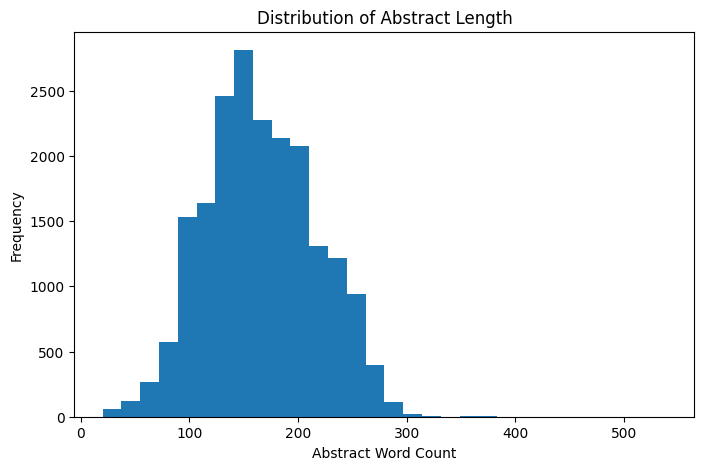

In [5]:
df["abstract_word_count"] = df["abstract"].fillna("").apply(lambda x: len(str(x).split()))

print(df["abstract_word_count"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["abstract_word_count"], bins=30)
plt.xlabel("Abstract Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Abstract Length")
plt.show()

## Apply Shared Preprocessing to All Abstracts

The same base preprocessing is applied to all documents to ensure consistency across later topic models. This shared preprocessing includes text cleaning, tokenization, stopword removal, and lemmatization.

At this stage, only general preprocessing is applied. Phrase modelling such as bigrams and trigrams will be performed later within each primary category, since meaningful phrases may differ across categories.

### Acronym Expansion

Research abstracts often contain acronyms (e.g., "convolutional neural network (CNN)"), which can reduce topic modelling quality.

We address this by:
- Detecting patterns of the form **"full term (acronym)"**
- Converting the full term into a single token using underscores  
  → `convolutional_neural_network`
- Replacing with both forms:  
  → `cnn convolutional_neural_network`
- Expanding subsequent acronym mentions similarly

This improves consistency and helps LDA/NMF capture more meaningful topics by preserving key domain concepts.

In [47]:
import re

def normalize_token(token):
    return re.sub(r'[^a-z0-9\-]', '', token.lower())

def acronym_is_valid(acr):
    # safer: mostly alphabetic acronyms only
    # skips things like 3d unless you explicitly want them
    return acr.isalpha() and 2 <= len(acr) <= 10

def build_initials(words):
    initials = ""
    for w in words:
        w = normalize_token(w)
        if w:
            initials += w[0]
    return initials

def best_definition_suffix(full_term, acronym):
    """
    From a longer candidate phrase, find the shortest suffix whose initials
    match the acronym. Example:
    'as a polymer in a globular state' + 'gs' -> 'globular state'
    """
    words = [w for w in full_term.split() if normalize_token(w)]
    acr = acronym.lower()

    # try suffixes from shortest reasonable length to longest
    for start in range(len(words)):
        suffix = words[start:]
        if len(suffix) < 2:
            continue
        initials = build_initials(suffix)
        if initials == acr:
            return " ".join(suffix)

    return None

def expand_acronyms_keep_both_safe(text):
    if not isinstance(text, str):
        return ""

    text_l = text.lower()

    # capture up to 8 words before acronym
    pattern = re.compile(
        r'((?:\b[a-z][a-z0-9\-]*\b(?:\s+|$)){1,8})\(([a-z0-9\-]{2,10})\)'
    )

    acronym_map = {}

    for match in pattern.finditer(text_l):
        full_term = match.group(1).strip()
        acronym = match.group(2).strip()

        if not acronym_is_valid(acronym):
            continue

        best_def = best_definition_suffix(full_term, acronym)
        if not best_def:
            continue

        full_term_clean = "_".join(best_def.split())
        acronym_map[acronym] = full_term_clean

    def replace_definition(match):
        full_term = match.group(1).strip()
        acronym = match.group(2).strip()

        if acronym not in acronym_map:
            return match.group(0)

        return f"{acronym} {acronym_map[acronym]}"

    text_l = pattern.sub(replace_definition, text_l)

    for acr, full_clean in acronym_map.items():
        text_l = re.sub(
            rf'\b{re.escape(acr)}\b(?!\s+{re.escape(full_clean)})',
            f"{acr} {full_clean}",
            text_l
        )

    return text_l

df['text_acronym_expanded'] = df['text'].apply(expand_acronyms_keep_both_safe)

In [49]:
for idx, row in df[['text','text_acronym_expanded','tokens_clean']].head(5).iterrows():
    print(f"--- ROW {idx} ---")
    print("ORIG   :", row['text'])
    print("EXPAND :", row['text_acronym_expanded'])
    print("TOKENS :", row['tokens_clean'])
    print()


--- ROW 0 ---
ORIG   : holographic bound and protein linguistics the holographic bound in physics constrains the complexity of life. the finite storage capability of information in the observable universe requires the protein linguistics in the evolution of life. we find that the evolution of genetic code determines the variance of amino acid frequencies and genomic gc content among species. the elegant linguistic mechanism is confirmed by the experimental observations based on all known entire proteomes.
EXPAND : holographic bound and protein linguistics the holographic bound in physics constrains the complexity of life. the finite storage capability of information in the observable universe requires the protein linguistics in the evolution of life. we find that the evolution of genetic code determines the variance of amino acid frequencies and genomic gc content among species. the elegant linguistic mechanism is confirmed by the experimental observations based on all known entire pro

In [50]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import lda_nmf_preprocessing

df["tokens_clean"] = df["text_acronym_expanded"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(x)
)

In [51]:
from collections import Counter
remaining = df['text_acronym_expanded'].fillna('').str.contains(r'\([a-z0-9]{2,10}\)', regex=True).sum()
print("Remaining parenthetical acronyms:", remaining)
all_tokens = [t for doc in df['tokens_clean'] if isinstance(doc, list) for t in doc]
print("Top underscore/hyphen tokens:", Counter([t for t in all_tokens if '_' in t or '-' in t]).most_common(20)[:10])

Remaining parenthetical acronyms: 8968
Top underscore/hyphen tokens: [('state-of-the-art', 1766), ('real-time', 1149), ('large-scale', 1132), ('real-world', 1054), ('artificial_intelligence', 786), ('data-driven', 723), ('trade-off', 643), ('self-supervised', 591), ('fine-tuning', 580), ('end-to-end', 575)]


In [52]:
df[["text_acronym_expanded", "tokens_clean"]].head(20)

,text_acronym_expanded,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, model, nucleotide, ..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, approa..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


## Inspect Frequent Terms After Preprocessing

We inspect the most common terms after preprocessing to identify whether additional custom stopwords may be required. If the most frequent terms are overly generic academic words, they may later be added to the stopword list.

In [53]:
all_words = [word for doc in df["tokens_clean"] for word in doc]
word_freq = Counter(all_words)

word_freq.most_common(30)

[('model', 25986),
 ('data', 13272),
 ('method', 13057),
 ('system', 10906),
 ('using', 9795),
 ('result', 9180),
 ('approach', 9139),
 ('network', 8619),
 ('study', 8141),
 ('framework', 8128),
 ('performance', 7797),
 ('learning', 7513),
 ('analysis', 7114),
 ('show', 6772),
 ('paper', 6484),
 ('dynamic', 5955),
 ('proposed', 5701),
 ('information', 5622),
 ('protein', 5548),
 ('structure', 5396),
 ('across', 5304),
 ('based', 5204),
 ('neural', 4977),
 ('effect', 4975),
 ('design', 4794),
 ('two', 4785),
 ('however', 4653),
 ('propose', 4652),
 ('control', 4639),
 ('time', 4635)]

In [54]:
extra_stopwords = [
    "model", "data", "method", "approach", "result",
    "study", "paper", "using", "based", "proposed",
    "show", "system", "framework", "analysis",
    "performance"
]

df["tokens_clean"] = df["text_acronym_expanded"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(
        x,
        extra_stopwords=extra_stopwords
    )
)

In [55]:
df[["text_acronym_expanded", "tokens_clean"]].head(20)

,text_acronym_expanded,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, nucleotide, sequenc..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, codon,..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


In [56]:
# 1. check whether model is still in cleaned tokens
sum("model" in doc for doc in df["tokens_clean"])

0

## Select One Primary Category for Topic Modelling

Topic modelling is performed separately for each primary category. Therefore, after shared preprocessing has been completed on the full dataset, we isolate one category and build a category-specific LDA model.

This design allows the discovered topics to reflect sub-themes within a category rather than broad differences between categories.

In [57]:
selected_category = "econ.EM"   # change this as needed

cat_df = df[df["primary_category"] == selected_category].copy()
cat_docs = cat_df["tokens_clean"].tolist()

print("Selected category:", selected_category)
print("Number of documents:", len(cat_docs))

Selected category: econ.EM
Number of documents: 2000


## Build Category-Specific Bigrams and Trigrams

Phrase modelling is performed separately within the selected category. This is because meaningful multi-word expressions may vary across different research domains.

For example, a phrase such as `neural_network` may be important in one category, while another category may contain different characteristic phrases.

We therefore explore:
- unigrams only
- unigrams + bigrams
- unigrams + bigrams + trigrams

In [58]:
print(type(cat_docs))
print(type(cat_docs[0]))
print(cat_docs[0])

<class 'list'>
<class 'list'>
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic', 'activity', 'climate', 'change', 'complex', 'possibility', 'causality', 'running', 'direction', 'starting', 'economic', 'activity', 'channel', 'relate', 'economic', 'activity', 'climate', 'change', 'energy', 'consumption', 'consequent', 'pollution', 'hence', 'first', 'describe', 'main', 'econometric', 'contribution', 'interaction', 'economic', 'activity', 'energy', 'consumption', 'moving', 'describing', 'contribution', 'interaction', 'economic', 'activity', 'pollution', 'finally', 'look', 'main', 'relationship', 'climate', 'change', 'economic', 'activity', 'important', 'consequence', 'climate', 'change'

In [59]:
bigram_phrases = Phrases(cat_docs, min_count=5, threshold=10)
bigram_model = Phraser(bigram_phrases)

docs_bigram = [bigram_model[doc] for doc in cat_docs]

trigram_phrases = Phrases(docs_bigram, min_count=5, threshold=10)
trigram_model = Phraser(trigram_phrases)

docs_trigram = [trigram_model[doc] for doc in docs_bigram]

In [60]:
print("Original tokens:")
print(cat_docs[0][:30])

print("\nWith bigrams:")
print(docs_bigram[0][:30])

print("\nWith trigrams:")
print(docs_trigram[0][:30])

Original tokens:
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic']

With bigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic_activity', 'climate_change', 'complex', 'possibility', 'causality']

With trigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'r

In [61]:
bigram_tokens = [token for doc in docs_bigram for token in doc if "_" in token]
trigram_tokens = [token for doc in docs_trigram for token in doc if token.count("_") >= 2]

print("Top bigrams:")
print(Counter(bigram_tokens).most_common(20))

print("\nTop trigrams:")
print(Counter(trigram_tokens).most_common(20))

Top bigrams:
[('treatment_effect', 446), ('machine_learning', 319), ('monte_carlo', 249), ('time_series', 238), ('instrumental_variable', 192), ('empirical_application', 176), ('finite_sample', 160), ('fixed_effect', 145), ('causal_effect', 144), ('average_treatment', 128), ('causal_inference', 127), ('confidence_interval', 118), ('estimation_inference', 98), ('sample_size', 96), ('synthetic_control', 95), ('potential_outcome', 94), ('test_statistic', 86), ('impulse_response', 83), ('unobserved_heterogeneity', 83), ('standard_error', 78)]

Top trigrams:
[('average_treatment_effect', 92), ('heterogeneous_treatment_effect', 59), ('regression_discontinuity_design', 48), ('simulation_empirical_application', 38), ('two-way_fixed_effect', 38), ('average_treatment_effect_treated', 35), ('ate_average_treatment_effect', 35), ('local_average_treatment_effect', 33), ('treatment_effect_heterogeneity', 30), ('double_machine_learning', 30), ('two_empirical_application', 29), ('consistent_asymptotica

Bigram analysis reveals dominant themes such as causal inference (e.g., treatment_effect, instrumental_variable), statistical estimation (e.g., confidence_interval, standard_error), and time-series modelling.
Trigram analysis further refines these into specific methodologies, including regression_discontinuity_design, average_treatment_effect, and double_machine_learning, indicating a strong emphasis on both classical econometric techniques and modern machine learning-based approaches.

## Choose the Text Representation for LDA

LDA can be trained using different document representations. In this notebook, we compare phrase modelling choices and then select one final representation for the topic model.

For scientific abstracts, bigrams often improve topic interpretability, while trigrams may provide additional value only when meaningful three-word terms are common.

In [62]:
lda_docs = docs_bigram   # can switch to cat_docs or docs_trigram

## Create the Gensim Dictionary and Bag-of-Words Corpus

Gensim LDA requires:
- a dictionary that maps each token to an integer id
- a bag-of-words corpus that represents each document as token counts

Very rare words and overly common words are filtered out to reduce noise and improve topic quality.

In [63]:
dictionary = Dictionary(lda_docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(doc) for doc in lda_docs]

In [64]:
print("Dictionary size:", len(dictionary))
print("Sample document BoW:", corpus[0][:10])

Dictionary size: 4275
Sample document BoW: [(0, 1), (1, 1), (2, 2), (3, 1), (4, 6), (5, 1), (6, 1), (7, 4), (8, 1), (9, 1)]


## Train and Evaluate LDA Models

LDA requires the number of topics to be specified in advance. To identify a suitable value, multiple models are trained with different topic numbers and evaluated using coherence score.

Coherence measures how semantically related the top words within a topic are. Higher coherence generally indicates more interpretable topics.

In [65]:
def compute_coherence_values(corpus, dictionary, texts, topic_range):
    results = []

    for num_topics in topic_range:
        lda_model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            random_state=42,
            chunksize=100,
            passes=10,
            alpha="auto"
        )

        coherence_model = CoherenceModel(
            model=lda_model,
            texts=texts,
            dictionary=dictionary,
            coherence="c_v"
        )

        coherence_score = coherence_model.get_coherence()

        results.append({
            "num_topics": num_topics,
            "model": lda_model,
            "coherence": coherence_score
        })

        print(f"num_topics={num_topics}, coherence={coherence_score:.4f}")

    return results

In [66]:
topic_range = range(2, 11)

results = compute_coherence_values(
    corpus=corpus,
    dictionary=dictionary,
    texts=lda_docs,
    topic_range=topic_range
)

num_topics=2, coherence=0.3957
num_topics=3, coherence=0.4408
num_topics=4, coherence=0.4059
num_topics=5, coherence=0.3750
num_topics=6, coherence=0.3863
num_topics=7, coherence=0.3626
num_topics=8, coherence=0.3801
num_topics=9, coherence=0.3927
num_topics=10, coherence=0.3774


In [67]:
results_df = pd.DataFrame([
    {"num_topics": r["num_topics"], "coherence": r["coherence"]}
    for r in results
])

results_df

,num_topics,coherence
0,2,0.395736
1,3,0.440754
2,4,0.405922
3,5,0.375020
4,6,0.386283
5,7,0.362578
6,8,0.380055
7,9,0.392740
8,10,0.377391


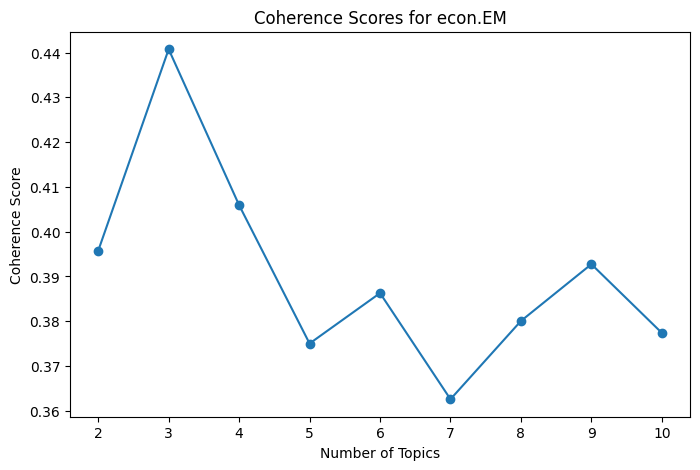

In [68]:
plt.figure(figsize=(8, 5))
plt.plot(results_df["num_topics"], results_df["coherence"], marker="o")
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.title(f"Coherence Scores for {selected_category}")
plt.xticks(results_df["num_topics"])
plt.show()

## Select the Best LDA Model

The model with the highest coherence score is selected as the best candidate. However, coherence alone is not sufficient, so manual inspection of topic meaning is also necessary.

In [69]:
best_result = max(results, key=lambda x: x["coherence"])
best_lda_model = best_result["model"]

print("Best number of topics:", best_result["num_topics"])
print("Best coherence:", round(best_result["coherence"], 4))

Best number of topics: 3
Best coherence: 0.4408


## Inspect Learned Topics

The top words for each topic are printed to evaluate whether the topics are meaningful, interpretable, and distinct from one another.

In [70]:
for topic_id, topic_words in best_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.007*"dynamic" + 0.006*"forecast" + 0.006*"market" + 0.006*"economic" + 0.006*"forecasting" + 0.006*"price" + 0.005*"across" + 0.005*"risk" + 0.005*"network" + 0.004*"effect"

Topic 1: 0.016*"effect" + 0.012*"outcome" + 0.011*"treatment" + 0.010*"treatment_effect" + 0.009*"estimator" + 0.009*"estimate" + 0.009*"assumption" + 0.007*"design" + 0.007*"policy" + 0.007*"setting"

Topic 2: 0.018*"estimator" + 0.014*"test" + 0.013*"estimation" + 0.011*"inference" + 0.007*"regression" + 0.007*"function" + 0.006*"parameter" + 0.006*"distribution" + 0.006*"simulation" + 0.006*"factor"



In [71]:
# re run model with doc_trigram to compare 

selected_category = "econ.EM"   # change this as needed

tri_lda_docs = docs_trigram

tri_dictionary = Dictionary(tri_lda_docs)
tri_dictionary.filter_extremes(no_below=5, no_above=0.5)

tri_corpus = [tri_dictionary.doc2bow(doc) for doc in tri_lda_docs]

refined_lda_model = LdaModel(
    corpus=tri_corpus,
    id2word=tri_dictionary,
    num_topics=3,
    random_state=42,
    chunksize=100,
    passes=10,
    alpha="auto",
    per_word_topics=True
)

for topic_id, topic_words in refined_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.008*"dynamic" + 0.006*"forecast" + 0.006*"price" + 0.006*"market" + 0.006*"forecasting" + 0.006*"economic" + 0.005*"across" + 0.005*"risk" + 0.005*"shock" + 0.004*"effect"

Topic 1: 0.012*"outcome" + 0.011*"effect" + 0.010*"treatment" + 0.009*"treatment_effect" + 0.009*"identification" + 0.009*"estimate" + 0.008*"policy" + 0.008*"assumption" + 0.007*"design" + 0.006*"setting"

Topic 2: 0.023*"estimator" + 0.014*"estimation" + 0.012*"test" + 0.011*"inference" + 0.007*"regression" + 0.007*"parameter" + 0.006*"function" + 0.006*"simulation" + 0.005*"panel" + 0.005*"procedure"



Although trigram modelling captures more granular domain-specific phrases, it introduces sparsity that weakens topic coherence and separability. Empirically, the bigram-based LDA produced more stable and interpretable topics, with clearer thematic distinctions. Hence, bigrams were adopted as the final representation, as they offer an optimal trade-off between expressiveness and model reliability.

## Assign a Dominant Topic to Each Document

To better understand the model output, each document is assigned its most probable topic. This allows us to inspect topic distribution and review example abstracts belonging to each topic.

In [72]:
def get_dominant_topic(lda_model, corpus):
    dominant_topics = []

    for bow in corpus:
        topic_probs = lda_model.get_document_topics(bow)
        dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
        dominant_topics.append(dominant_topic)

    return dominant_topics

cat_df = cat_df.reset_index(drop=True)
cat_df["dominant_topic"] = get_dominant_topic(best_lda_model, corpus)

cat_df[["abstract", "dominant_topic"]].head()

,abstract,dominant_topic
0,"In this paper, we survey recent econometric co...",0
1,This paper studies inference in randomized con...,1
2,The Neyman Allocation is used in many papers o...,1
3,Vector autogressions (VARs) are widely applied...,0
4,We propose a method to debias estimators based...,2


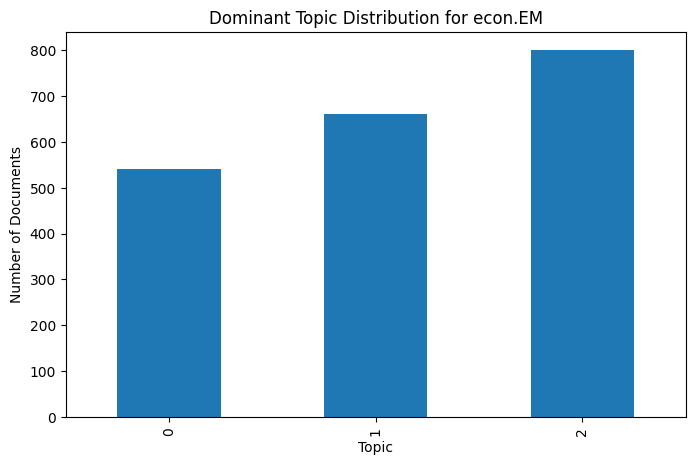

In [73]:
topic_dist = cat_df["dominant_topic"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
topic_dist.plot(kind="bar")
plt.xlabel("Topic")
plt.ylabel("Number of Documents")
plt.title(f"Dominant Topic Distribution for {selected_category}")
plt.show()

## Inspect Sample Documents for Each Topic

Topic keywords alone may not fully capture the meaning of each topic. Therefore, sample abstracts are reviewed for each dominant topic to validate whether the grouping is coherent and interpretable.

In [74]:
for topic_id in sorted(cat_df["dominant_topic"].unique()):
    print("=" * 80)
    print(f"TOPIC {topic_id}")
    print("=" * 80)

    topic_samples = cat_df[cat_df["dominant_topic"] == topic_id]["abstract"].head(3).tolist()

    for i, sample in enumerate(topic_samples, 1):
        print(f"\nSample {i}:")
        print(sample[:700])
        print()

TOPIC 0

Sample 1:
In this paper, we survey recent econometric contributions to measure the relationship between economic activity and climate change. Due to the critical relevance of these effects for the well-being of future generations, there is an explosion of publications devoted to measuring this relationship and its main channels. The relation between economic activity and climate change is complex with the possibility of causality running in both directions. Starting from economic activity, the channels that relate economic activity and climate change are energy consumption and the consequent pollution. Hence, we first describe the main econometric contributions about the interactions between economic 


Sample 2:
Vector autogressions (VARs) are widely applied when it comes to modeling and forecasting macroeconomic variables. In high dimensions, however, they are prone to overfitting. Bayesian methods, more concretely shrinkage priors, have shown to be successful in improving p

### Qualitative Evaluation of Topics

Manual inspection of representative documents per topic demonstrates strong intra-topic coherence and inter-topic distinction. Topic 0 is dominated by methodological econometric research, including estimation theory and statistical inference. Topic 1 captures applied and interdisciplinary work, linking economic phenomena such as climate change and financial systems with advanced computational techniques. Topic 2 clearly represents causal inference and experimental design, with a focus on randomized trials and treatment effect estimation.

These findings indicate that the bigram-based LDA model produces semantically meaningful and well-separated topics, aligning closely with known subfields in econometrics.

### Limitations of LDA Observed

One limitation observed is the presence of relatively broad topics, such as Topic 1, which combines applied economic domains (e.g., climate and finance) with machine learning-based methods. This can be attributed to LDA’s bag-of-words assumption, which ignores contextual and semantic relationships between words. As a result, documents from different subfields that share common vocabulary may be grouped into the same topic.

Additionally, the need to predefine the number of topics forces LDA to compress diverse themes into a limited set of topics, reducing granularity. This explains why applied and interdisciplinary research areas are not fully separated in the model output.

## Compare Unigram, Bigram, and Trigram Representations

To justify the phrase modelling choice, we compare coherence scores across unigram-only, bigram-enhanced, and trigram-enhanced representations.

This helps determine whether trigrams provide real improvement or merely increase sparsity.

In [75]:
def evaluate_representation(docs, num_topics):
    dictionary = Dictionary(docs)
    dictionary.filter_extremes(no_below=5, no_above=0.5)
    corpus = [dictionary.doc2bow(doc) for doc in docs]

    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        chunksize=100,
        passes=10,
        alpha="auto"
    )

    coherence_model = CoherenceModel(
        model=lda_model,
        texts=docs,
        dictionary=dictionary,
        coherence="c_v"
    )

    return coherence_model.get_coherence()


comparison = pd.DataFrame({
    "representation": ["unigram", "bigram", "trigram"],
    "coherence": [
        evaluate_representation(cat_docs, best_result["num_topics"]),
        evaluate_representation(docs_bigram, best_result["num_topics"]),
        evaluate_representation(docs_trigram, best_result["num_topics"])
    ]
})

comparison

,representation,coherence
0,unigram,0.463553
1,bigram,0.440754
2,trigram,0.401499


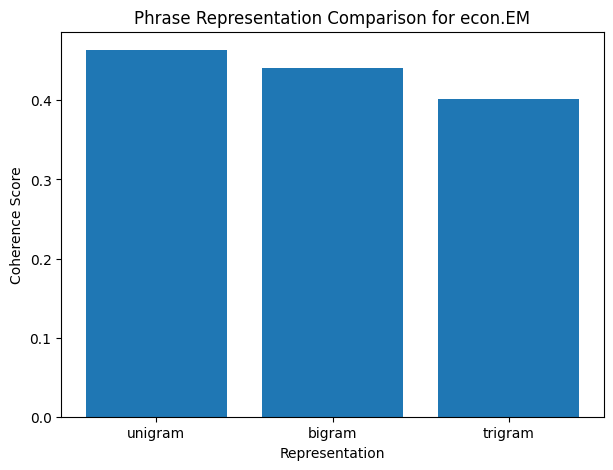

In [76]:
plt.figure(figsize=(7, 5))
plt.bar(comparison["representation"], comparison["coherence"])
plt.xlabel("Representation")
plt.ylabel("Coherence Score")
plt.title(f"Phrase Representation Comparison for {selected_category}")
plt.show()

In [77]:
import sys
!{sys.executable} -m pip install pyLDAvis

In [78]:
# import os
# import pandas as pd
# import matplotlib.pyplot as plt
# import pyLDAvis
# import pyLDAvis.gensim_models as gensimvis

# from gensim.corpora import Dictionary
# from gensim.models import LdaModel, CoherenceModel
# from gensim.models.phrases import Phrases, Phraser

# def run_lda_group(df, group_col, topic_range=None):

#     if topic_range is None:
#         if group_col == "broad_subject":
#             topic_range = range(2, 16)   # max 15
#         elif group_col == "primary_category":
#             topic_range = range(2, 6)    # max 5
#         else:
#             topic_range = range(2, 9)    # fallback

#     results = []

#     for group in df[group_col].unique():

#         group_df = df[df[group_col] == group]
#         docs = group_df["tokens_clean"].tolist()

#         if len(docs) < 20:
#             continue

#         # bigram
#         bigram = Phraser(Phrases(docs, min_count=5, threshold=10))
#         docs = [bigram[d] for d in docs]

#         dictionary = Dictionary(docs)
#         dictionary.filter_extremes(no_below=5, no_above=0.5)
#         corpus = [dictionary.doc2bow(d) for d in docs]

#         coherence_scores = []
#         models = []

#         for k in topic_range:
#             model = LdaModel(
#                 corpus=corpus,
#                 id2word=dictionary,
#                 num_topics=k,
#                 random_state=42,
#                 passes=10
#             )

#             cm = CoherenceModel(
#                 model=model,
#                 texts=docs,
#                 dictionary=dictionary,
#                 coherence="c_v"
#             )

#             score = cm.get_coherence()

#             coherence_scores.append(score)
#             models.append(model)

#         best_idx = coherence_scores.index(max(coherence_scores))
#         best_k = list(topic_range)[best_idx]
#         best_model = models[best_idx]

#         print(f"\n=== {group} ===")
#         for k, s in zip(topic_range, coherence_scores):
#             print(f"k={k} → {s:.4f}")

#         print(f"BEST k={best_k}")

#         for t_id, words in best_model.print_topics(num_words=10):
#             print(f"Topic {t_id}: {words}")

#         results.append({
#             "group": group,
#             "best_k": best_k,
#             "best_coherence": max(coherence_scores)
#         })

#     return pd.DataFrame(results)

In [79]:
# broad_results = run_lda_group(df, "broad_subject")

In [80]:
# primary_results = run_lda_group(df, "primary_category")

# Topic Modelling for all categories

In [83]:
# deleted saved models to re-run with new preprocessing
import shutil
shutil.rmtree("lda_saved_models")   # deletes all saved models (then re-run pipeline)

In [84]:
import os
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from IPython.display import display, HTML

# -----------------------------
# settings
# -----------------------------
SAVE_DIR = "lda_saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

TOPIC_RANGE = range(2, 11)   # adjust if needed
NUM_WORDS = 15 
PASSES = 6                  # lower = faster
RANDOM_STATE = 42
CHUNKSIZE = 100

all_topic_results = []
all_topic_word_dist = []
all_doc_results = []
all_topic_distribution = []
all_model_scores = []

for category in df["primary_category"].unique():

    print(f"\n{'='*80}")
    print(f"Category: {category}")
    print(f"{'='*80}")

    cat_df = df[df["primary_category"] == category].copy().reset_index(drop=True)
    cat_docs = cat_df["tokens_clean"].tolist()

    if len(cat_docs) < 20:
        print("Skipped: too few documents")
        continue

    # -----------------------------
    # bigram
    # -----------------------------
    bigram_model = Phraser(Phrases(cat_docs, min_count=5, threshold=10))
    docs_bigram = [bigram_model[doc] for doc in cat_docs]

    # -----------------------------
    # dictionary + corpus
    # -----------------------------
    dictionary = Dictionary(docs_bigram)
    dictionary.filter_extremes(no_below=5, no_above=0.5)
    corpus = [dictionary.doc2bow(doc) for doc in docs_bigram]

    if len(dictionary) == 0:
        print("Skipped: empty dictionary after filtering")
        continue

    best_model = None
    best_k = None
    best_cv = -1

    # -----------------------------
    # tune k using c_v only
    # -----------------------------
    for k in TOPIC_RANGE:
        model_path = os.path.join(SAVE_DIR, f"{category.replace('.', '_')}_k{k}.gensim")

        if os.path.exists(model_path):
            lda_model = LdaModel.load(model_path)
        else:
            lda_model = LdaModel(
                corpus=corpus,
                id2word=dictionary,
                num_topics=k,
                passes=PASSES,
                random_state=RANDOM_STATE,
                chunksize=CHUNKSIZE,
                alpha="auto",
                eval_every=None
            )
            lda_model.save(model_path)

        cv_score = CoherenceModel(
            model=lda_model,
            texts=docs_bigram,
            dictionary=dictionary,
            coherence="c_v"
        ).get_coherence()

        all_model_scores.append({
            "category": category,
            "k": k,
            "c_v": round(cv_score, 4)
        })

        if cv_score > best_cv:
            best_cv = cv_score
            best_k = k
            best_model = lda_model

    # -----------------------------
    # compute npmi only for best model
    # -----------------------------
    npmi_score = CoherenceModel(
        model=best_model,
        texts=docs_bigram,
        dictionary=dictionary,
        coherence="c_npmi"
    ).get_coherence()

    print(f"Best k      : {best_k}")
    print(f"Best c_v    : {best_cv:.4f}")
    print(f"Best c_npmi : {npmi_score:.4f}")

    # update score table so best_k row also has npmi
    for row in all_model_scores:
        if row["category"] == category and row["k"] == best_k:
            row["c_npmi"] = round(npmi_score, 4)
        elif row["category"] == category and "c_npmi" not in row:
            row["c_npmi"] = None

    # -----------------------------
    # topic word results
    # -----------------------------
    topic_word_rows = []

    for topic_id in range(best_model.num_topics):
        topic_terms = best_model.show_topic(topic_id, topn=NUM_WORDS)

        pretty_terms = []
        for rank, (word, weight) in enumerate(topic_terms, start=1):
            topic_word_rows.append({
                "category": category,
                "topic_id": topic_id,
                "rank": rank,
                "word": word,
                "weight": round(weight, 4)
            })
            pretty_terms.append(f"{word} ({weight:.4f})")

        all_topic_results.append({
            "category": category,
            "topic_id": topic_id,
            "topic_words": ", ".join(pretty_terms)
        })

    all_topic_word_dist.extend(topic_word_rows)

    # -----------------------------
    # document-topic results
    # -----------------------------
    dominant_topics = []

    for i, bow in enumerate(corpus):
        topic_probs = best_model.get_document_topics(bow, minimum_probability=0)

        dominant_topic, dominant_prob = max(topic_probs, key=lambda x: x[1])
        dominant_topics.append(dominant_topic)

        row = {
            "category": category,
            "doc_index_within_category": i,
            "dominant_topic": dominant_topic,
            "dominant_topic_prob": round(dominant_prob, 4),
            "title": cat_df.loc[i, "title"] if "title" in cat_df.columns else None,
            "abstract": cat_df.loc[i, "abstract"] if "abstract" in cat_df.columns else None
        }

        for topic_id, prob in topic_probs:
            row[f"topic_{topic_id}_prob"] = round(prob, 4)

        all_doc_results.append(row)

    # -----------------------------
    # topic distribution table
    # -----------------------------
    topic_dist_df = (
        pd.Series(dominant_topics, name="dominant_topic")
        .value_counts()
        .sort_index()
        .rename_axis("topic_id")
        .reset_index(name="doc_count")
    )

    topic_dist_df["doc_pct"] = (topic_dist_df["doc_count"] / len(corpus) * 100).round(2)
    topic_dist_df["category"] = category
    topic_dist_df["best_k"] = best_k
    topic_dist_df["best_c_v"] = round(best_cv, 4)
    topic_dist_df["best_c_npmi"] = round(npmi_score, 4)

    all_topic_distribution.extend(topic_dist_df.to_dict("records"))

# -----------------------------
# save all outputs
# -----------------------------
topics_df = pd.DataFrame(all_topic_results)
topic_word_dist_df = pd.DataFrame(all_topic_word_dist)
docs_df = pd.DataFrame(all_doc_results)
topic_distribution_df = pd.DataFrame(all_topic_distribution)
model_scores_df = pd.DataFrame(all_model_scores)

topics_df.to_csv("lda_all_topics.csv", index=False)
topic_word_dist_df.to_csv("lda_all_topic_word_distribution.csv", index=False)
docs_df.to_csv("lda_all_doc_topics.csv", index=False)
topic_distribution_df.to_csv("lda_topic_distribution.csv", index=False)
model_scores_df.to_csv("lda_model_scores_by_k.csv", index=False)

print("\nSaved files:")
print("- lda_all_topics.csv")
print("- lda_all_topic_word_distribution.csv")
print("- lda_all_doc_topics.csv")
print("- lda_topic_distribution.csv")
print("- lda_model_scores_by_k.csv")


Category: q-bio.GN
Best k      : 3
Best c_v    : 0.4023
Best c_npmi : -0.0017

Category: q-bio.BM
Best k      : 3
Best c_v    : 0.4617
Best c_npmi : 0.0180

Category: econ.TH
Best k      : 8
Best c_v    : 0.3690
Best c_npmi : -0.0124

Category: econ.EM
Best k      : 3
Best c_v    : 0.4442
Best c_npmi : 0.0114

Category: q-bio.NC
Best k      : 9
Best c_v    : 0.3862
Best c_npmi : -0.0496

Category: econ.GN
Best k      : 4
Best c_v    : 0.4277
Best c_npmi : 0.0120

Category: eess.AS
Best k      : 8
Best c_v    : 0.3662
Best c_npmi : -0.0470

Category: eess.IV
Best k      : 8
Best c_v    : 0.3808
Best c_npmi : -0.0769

Category: eess.SP
Best k      : 4
Best c_v    : 0.4325
Best c_npmi : -0.0009

Category: eess.SY
Best k      : 5
Best c_v    : 0.4047
Best c_npmi : 0.0078

Saved files:
- lda_all_topics.csv
- lda_all_topic_word_distribution.csv
- lda_all_doc_topics.csv
- lda_topic_distribution.csv
- lda_model_scores_by_k.csv


In [85]:
best_scores_df = (
    model_scores_df
    .loc[model_scores_df.groupby("category")["c_v"].idxmax()]
    .sort_values("category")
    .reset_index(drop=True)
)

display(best_scores_df)

,category,k,c_v,c_npmi
0,econ.EM,3,0.4442,0.0114
1,econ.GN,4,0.4277,0.0120
2,econ.TH,8,0.3690,-0.0124
3,eess.AS,8,0.3662,-0.0470
4,eess.IV,8,0.3808,-0.0769
5,eess.SP,4,0.4325,-0.0009
6,eess.SY,5,0.4047,0.0078
7,q-bio.BM,3,0.4617,0.0180
8,q-bio.GN,3,0.4023,-0.0017
9,q-bio.NC,9,0.3862,-0.0496


In [86]:
topic_word_dist_df = pd.read_csv("lda_all_topic_word_distribution.csv")

for category in topic_word_dist_df["category"].unique():
    cat_df = topic_word_dist_df[topic_word_dist_df["category"] == category].copy()

    topic_tables_html = []

    for topic_id in sorted(cat_df["topic_id"].unique()):
        topic_df = cat_df[cat_df["topic_id"] == topic_id][["rank", "word", "weight"]].copy()
        topic_df = topic_df.rename(columns={"weight": "probability"})

        topic_html = f"""
        <div style="
            display:inline-block;
            vertical-align:top;
            margin-right:20px;
            margin-bottom:20px;
        ">
            <h4 style="margin-bottom:8px;">Topic {topic_id}</h4>
            {topic_df.to_html(index=False)}
        </div>
        """
        topic_tables_html.append(topic_html)

    display(HTML(f"""
    <div style="margin-bottom:10px;">
        <h3>{category}</h3>
    </div>
    <div>
        {''.join(topic_tables_html)}
    </div>
    """))

rank,word,probability
1,gene,0.0205
2,cell,0.0084
3,prediction,0.0074
4,gene_expression,0.0066
5,disease,0.0063
6,cancer,0.0056
7,across,0.0055
8,network,0.0053
9,feature,0.0050
10,machine_learning,0.0045


rank,word,probability
1,dynamic,0.0128
2,structure,0.0104
3,rna,0.0086
4,simulation,0.0081
5,function,0.0062
6,folding,0.0061
7,interaction,0.0057
8,state,0.0057
9,energy,0.0053
10,dna,0.0053


rank,word,probability
1,optimal,0.0287
2,value,0.0275
3,type,0.0238
4,distribution,0.0182
5,information,0.0173
6,cost,0.0141
7,design,0.0137
8,buyer,0.0107
9,auction,0.0105
10,seller,0.0103


rank,word,probability
1,dynamic,0.0074
2,forecast,0.0057
3,market,0.0057
4,economic,0.0055
5,forecasting,0.0055
6,price,0.0054
7,across,0.0049
8,risk,0.0047
9,network,0.0045
10,effect,0.0042


rank,word,probability
1,brain,0.0231
2,neural,0.0173
3,dynamic,0.0125
4,network,0.0114
5,state,0.0104
6,interaction,0.0092
7,structure,0.0091
8,pattern,0.0083
9,complex,0.0070
10,understanding,0.0069


rank,word,probability
1,artificial_intelligence,0.0092
2,cost,0.0080
3,research,0.0065
4,market,0.0060
5,innovation,0.0060
6,policy,0.0059
7,demand,0.0058
8,technology,0.0054
9,firm,0.0054
10,development,0.0045


rank,word,probability
1,speech_enhancement,0.0250
2,noise,0.0215
3,signal,0.0166
4,error,0.0150
5,algorithm,0.0104
6,robust,0.0095
7,hybrid,0.0095
8,degradation,0.0094
9,function,0.0072
10,clean,0.0067


rank,word,probability
1,accuracy,0.0121
2,feature,0.0111
3,deep_learning,0.0099
4,architecture,0.0091
5,attention,0.0067
6,network,0.0064
7,technique,0.0057
8,detection,0.0056
9,focus,0.0055
10,region,0.0052


rank,word,probability
1,signal,0.0164
2,estimation,0.0134
3,channel,0.0114
4,algorithm,0.0079
5,parameter,0.0069
6,structure,0.0059
7,noise,0.0051
8,error,0.0047
9,sparse,0.0046
10,waveform,0.0046


rank,word,probability
1,control,0.0259
2,dynamic,0.0134
3,state,0.0110
4,nonlinear,0.0105
5,controller,0.0104
6,condition,0.0079
7,function,0.0070
8,design,0.0069
9,guarantee,0.0067
10,linear,0.0065


In [87]:
topic_distribution_df = pd.read_csv("lda_topic_distribution.csv")
topic_distribution_df = topic_distribution_df.sort_values(["category", "topic_id"]).reset_index(drop=True)

display(topic_distribution_df)

,topic_id,doc_count,doc_pct,category,best_k,best_c_v,best_c_npmi
0,0,554,27.70,econ.EM,3,0.4442,0.0114
1,1,693,34.65,econ.EM,3,0.4442,0.0114
2,2,753,37.65,econ.EM,3,0.4442,0.0114
3,0,635,31.75,econ.GN,4,0.4277,0.0120
4,1,460,23.00,econ.GN,4,0.4277,0.0120
5,2,464,23.20,econ.GN,4,0.4277,0.0120
6,3,441,22.05,econ.GN,4,0.4277,0.0120
7,0,236,11.83,econ.TH,8,0.3690,-0.0124
8,1,304,15.24,econ.TH,8,0.3690,-0.0124
9,2,208,10.43,econ.TH,8,0.3690,-0.0124


Using category: eess.SY
--- eess.SY ---
Topic 0 (681 docs): control, dynamic, state, nonlinear, controller, condition, function, design, guarantee, linear
Topic 1 (515 docs): network, problem, learning, algorithm, demonstrate, optimization, training, via, however, complex
Topic 2 (213 docs): power, dynamic, frequency, voltage, grid, load, network, control, stability, fault
Topic 3 (305 docs): agent, control, safety, communication, environment, dynamic, architecture, design, adaptive, present
Topic 4 (286 docs): energy, cost, demand, battery, capacity, operation, scheduling, storage, operational, uncertainty


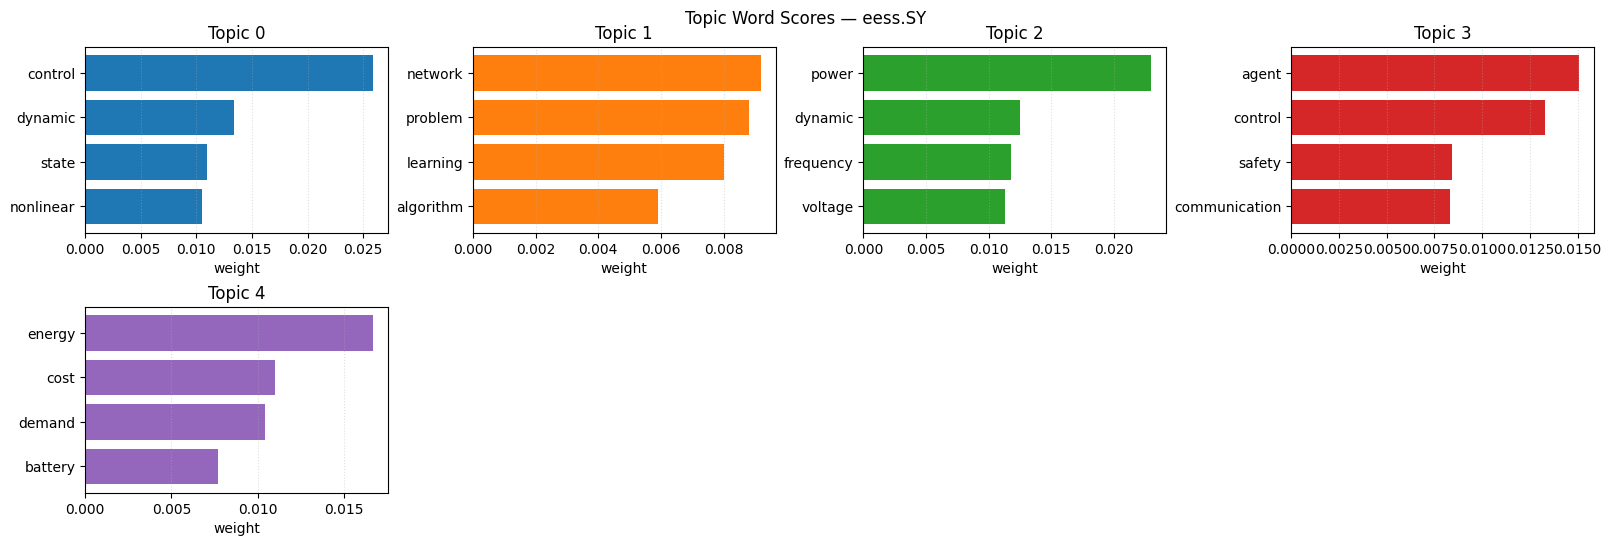

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import math

# paths (relative to this notebook)
topic_word_path = "lda_all_topic_word_distribution.csv"
topic_dist_path = "lda_topic_distribution.csv"
doc_topics_path = "lda_all_doc_topics.csv"  # fallback if doc counts missing

# load CSVs
tw = pd.read_csv(topic_word_path)
td = pd.read_csv(topic_dist_path)

# choose category (case-insensitive)
desired = "eess.SY"   # change if needed

def find_category_name(df, desired):
    d = desired.lower()
    uniques = list(df['category'].unique())
    for c in uniques:
        if c.lower() == d:
            return c
    for c in uniques:
        if d in c.lower():
            return c
    raise ValueError(f"No category matching {desired!r}. Available (sample): {uniques[:20]}")

cat = find_category_name(tw, desired)
print("Using category:", cat)

# subset topic-word rows
cat_words = tw[tw['category'] == cat].copy()
cat_words['rank'] = cat_words['rank'].astype(int)
cat_words = cat_words.sort_values(['topic_id', 'rank'])

# get per-topic doc counts (fallback to docs file if needed)
if 'doc_count' in td.columns and not td[td['category'] == cat].empty:
    doc_counts = td[td['category'] == cat].set_index('topic_id')['doc_count'].to_dict()
else:
    docs_df = pd.read_csv(doc_topics_path)
    docs_df = docs_df[docs_df['category'] == cat]
    doc_counts = docs_df['dominant_topic'].value_counts().to_dict()

# Print textual summary like your pasted example
top_print = 10
print(f"--- {cat} ---")
for topic_id in sorted(cat_words['topic_id'].unique()):
    words = cat_words[cat_words['topic_id'] == topic_id].sort_values('rank')['word'].tolist()[:top_print]
    words = [w.replace('_', ' ') for w in words]
    cnt = int(doc_counts.get(topic_id, 0))
    print(f"Topic {topic_id} ({cnt} docs): " + ", ".join(words))

# Plot horizontal bar charts (top N words per topic)
top_plot = 4
topics = sorted(cat_words['topic_id'].unique())
n_topics = len(topics)
ncols = min(4, n_topics)
nrows = math.ceil(n_topics / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*2.6), constrained_layout=True)
axes = axes.flatten() if n_topics > 1 else [axes]

cmap = plt.get_cmap('tab10')
for i, topic_id in enumerate(topics):
    ax = axes[i]
    df = cat_words[cat_words['topic_id'] == topic_id].sort_values('rank').head(top_plot)
    df = df[::-1]
    ax.barh(df['word'].str.replace('_', ' ', regex=False), df['weight'], color=cmap(i % 10))
    ax.set_title(f"Topic {topic_id}")
    ax.set_xlabel("weight")
    ax.grid(axis='x', linestyle=':', alpha=0.4)

for j in range(len(topics), len(axes)):
    axes[j].axis('off')

plt.suptitle(f"Topic Word Scores — {cat}", y=1.02)
plt.show()

# optional: save PNG
fig.savefig(f"{cat.replace('.', '_')}_topic_word_scores.png", bbox_inches='tight', dpi=150)